MLE, Gradient Descent on the Negative Log Likelihood


In [22]:
import numpy as np
import matplotlib.pyplot as plt
coin_toss=np.array([1,0,1,1,0])
def negative_log_likelihood(p, observations):
    p=np.clip(p,0.000001,0.999999)
    nll=-np.sum(observations * np.log(p)+ (1-observations)* np.log(1-p))
    return nll
true_mle=np.mean(coin_toss)

In [23]:
print("NLL when p is 0.4:", negative_log_likelihood(0.4,coin_toss))
print("NLL when p is 0.5:", negative_log_likelihood(0.5,coin_toss))
print("NLL when p is 0.6:", negative_log_likelihood(0.6,coin_toss))
print("NLL when p is 0.8:", negative_log_likelihood(0.8,coin_toss))
print(true_mle)

NLL when p is 0.4: 3.7705234431544463
NLL when p is 0.5: 3.4657359027997265
NLL when p is 0.6: 3.365058335046282
NLL when p is 0.8: 3.88830647881083
0.6


In [24]:
def nll_gradient(p, observations):
    number_of_heads=np.sum(observations)
    number_of_tails= len(observations)-number_of_heads
    gradient=(-number_of_heads/p + number_of_tails/(1-p))
    return gradient

In [25]:
print("Gradient at p=0.4 is ", nll_gradient(0.4, coin_toss))
print("Gradient at p=0.6 is ", nll_gradient(0.6, coin_toss))
print("Gradient at p=0.8 is ", nll_gradient(0.8, coin_toss))


Gradient at p=0.4 is  -4.166666666666666
Gradient at p=0.6 is  0.0
Gradient at p=0.8 is  6.250000000000002


Gradient Descent from Scratch


In [26]:
from time import perf_counter
p=0.5
learning_rate=0.01
number_of_iterations=100
p_history=[]
nll_history=[]
start_time=perf_counter()
for iterations in range(number_of_iterations):
    gradient=nll_gradient(p,coin_toss)
    p=p-learning_rate*gradient
    p=np.clip(p,0.000001,0.999999)
    current_nll=negative_log_likelihood(p,coin_toss)
    p_history.append(p)
    nll_history.append(current_nll)
end_time=perf_counter()
execution_time=end_time-start_time
print("estimated p",p)
print("Final nll:", nll_history[-1])
print("Direct MLE: ", np.mean(coin_toss))
print(f"execution time {execution_time:.10f} seconds")

estimated p 0.5999999999922886
Final nll: 3.3650583350462817
Direct MLE:  0.6
execution time 0.0029887080 seconds


In [27]:
for iteration in [0,1,2,4,9,19,29,49,99]:
    print(f"Iteration {iteration +1:3d}" f"p={p_history[iteration]:.6f}," f"NLL= {nll_history[iteration]:.6f}")


Iteration   1p=0.520000,NLL= 3.429718
Iteration   2p=0.536026,NLL= 3.406572
Iteration   3p=0.548887,NLL= 3.391663
Iteration   5p=0.567483,NLL= 3.375901
Iteration  10p=0.589679,NLL= 3.366162
Iteration  20p=0.598992,NLL= 3.365069
Iteration  30p=0.599902,NLL= 3.365058
Iteration  50p=0.599999,NLL= 3.365058
Iteration 100p=0.600000,NLL= 3.365058


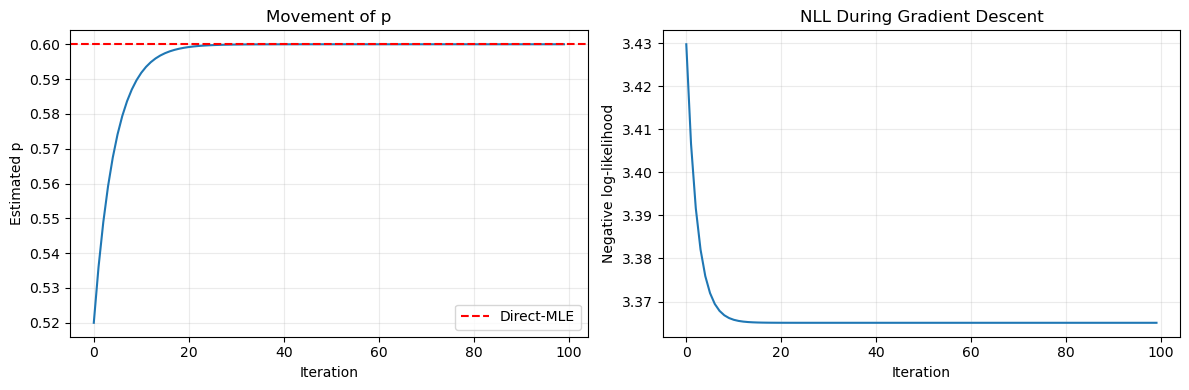

In [28]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(p_history)
plt.axhline(true_mle,color="red",linestyle="--", label="Direct-MLE")
plt.xlabel("Iteration")
plt.ylabel("Estimated p")
plt.title("Movement of p")
plt.grid(alpha=0.25)
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(nll_history)
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.title("NLL During Gradient Descent")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()